# Неделя 01. От бизнес-вопроса к воспроизводимому анализу

        **Кейс:** учебная служба поддержки хочет понять, сколько пользователи ждут ответа.
        Мы пройдём маленький цикл Data Science: вопрос → таблица → проверка → число → график → вывод.
        Первую модель ещё не обучаем: сначала нужно определить, что мы вообще измеряем.

        **Цель:** отличить анализ, ML и AI-систему; запустить Jupyter; прочитать небольшой CSV;
        сделать первый численный вывод и проверить воспроизводимость. Все данные синтетические.


## 1. Что такое задача, наблюдение и признак

        Data Science объединяет работу с данными, статистику и предметную постановку задачи.
        ML учится отображать признаки в прогноз по примерам. AI-система может включать ML,
        правила, интерфейс и действия. У этих терминов есть пересечения; одно не заменяет другое.

        В таблице одна **строка** — обращение; `channel` — признак;
        `wait_minutes` можно сделать **целевой переменной**, если прогноз нужен при поступлении.
        Сначала спрашиваем: кому нужен результат, в какой момент он используется и что считается успехом?


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import hashlib
import json

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_01_intro_ds_ai'):
            if candidate.name == 'week_01_intro_ds_ai' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_01_intro_ds_ai


## 2. Notebook — это исполняемый документ

        Markdown-ячейка содержит объяснение; Code-ячейка меняет состояние kernel.
        `Shift+Enter` запускает ячейку. Ошибка выполнения требует исправления причины,
        а не скрытия ячейки. В конце используйте **Restart Kernel → Run All**:
        это проверяет, что результат не зависит от забытых переменных.


In [2]:
data_path = DATA_DIR / "support_tickets.csv"
tickets = pd.read_csv(data_path, parse_dates=["created_date"])
display(tickets.head(8))
print("Строк:", len(tickets), "| Столбцов:", len(tickets.columns))


,ticket_id,created_date,channel,category,wait_minutes,resolution_minutes,satisfaction
0,T0001,2026-01-01,phone,access,17.2,11.9,4
1,T0002,2026-01-01,phone,access,14.0,3.0,3
2,T0003,2026-01-01,email,technical,35.7,35.1,3
3,T0004,2026-01-01,chat,access,9.2,7.5,5
4,T0005,2026-01-01,chat,payment,8.7,11.5,5
5,T0006,2026-01-02,chat,payment,3.9,11.9,5
6,T0007,2026-01-02,phone,technical,10.5,31.0,5
7,T0008,2026-01-02,email,access,32.3,9.9,4


Строк: 150 | Столбцов: 7


## 3. Не путать измерение с интерпретацией

        `wait_minutes` — количественная величина с единицей измерения.
        `satisfaction` — порядковая шкала от 1 до 5: разница между 1 и 2 не обязана
        значить то же, что между 4 и 5. Идентификатор обращения не является полезной числовой мерой.
        Словарь полей находится в `../datasets/README.md`.


In [3]:
schema = pd.DataFrame({"dtype": tickets.dtypes.astype(str),
                       "missing": tickets.isna().sum(),
                       "unique_values": tickets.nunique()})
display(schema)
# Это проверка контракта нашего конкретного учебного CSV.
assert tickets["ticket_id"].is_unique
assert tickets["wait_minutes"].gt(0).all()
assert tickets["satisfaction"].between(1, 5).all()


,dtype,missing,unique_values
ticket_id,str,0,150
created_date,datetime64[us],0,30
channel,str,0,3
category,str,0,3
wait_minutes,float64,0,112
resolution_minutes,float64,0,125
satisfaction,int64,0,4


## 4. Среднее и медиана отвечают на разные вопросы

        Среднее: $\bar{x}=\frac{1}{n}\sum_{i=1}^n x_i$.
        Медиана — центральное значение упорядоченной выборки (для чётного $n$ — среднее двух центральных).
        Большое ожидание одного клиента влияет на среднее сильнее, чем на медиану.
        Поэтому в отчёте покажем обе величины и объём выборки.


In [4]:
waits = tickets["wait_minutes"]
summary = pd.Series({"n": len(waits), "mean_minutes": waits.mean(),
                     "median_minutes": waits.median(), "min_minutes": waits.min(),
                     "p90_minutes": waits.quantile(0.90), "max_minutes": waits.max()})
display(summary.round(2).to_frame("value"))
# Вручную проверяем формулу среднего, не полагаясь на красивую таблицу.
manual_mean = sum(waits) / len(waits)
assert np.isclose(manual_mean, waits.mean())


,value
n,150.00
mean_minutes,18.06
median_minutes,14.40
min_minutes,1.00
p90_minutes,36.42
max_minutes,47.30


## 5. Распределение показывает то, что скрывает одно число

        Гистограмма считает, сколько обращений попало в каждый интервал ожидания.
        Вертикальные линии показывают среднее и медиану. Нельзя считать 90-й процентиль
        обещанием, что ровно 90% будущих обращений будут быстрее: это описание этой выборки.


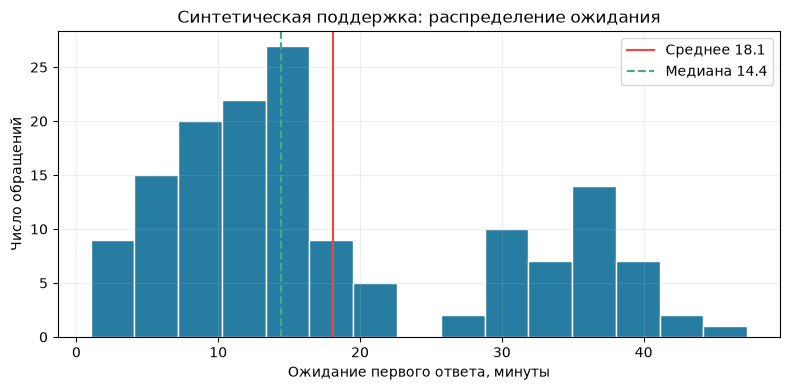

In [5]:
fig, ax = plt.subplots()
ax.hist(waits, bins=15, color="#277DA1", edgecolor="white")
ax.axvline(waits.mean(), color="#F94144", label=f"Среднее {waits.mean():.1f}")
ax.axvline(waits.median(), color="#43AA8B", linestyle="--", label=f"Медиана {waits.median():.1f}")
ax.set(xlabel="Ожидание первого ответа, минуты", ylabel="Число обращений",
       title="Синтетическая поддержка: распределение ожидания")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Переходим от общего среднего к группам

        Сравним каналы по одинаковым метрикам. Число обращений `n` обязательно:
        одинаковое среднее при 3 и 300 наблюдениях имеет разную устойчивость.
        Пока это описательное сравнение. Каналы могут отличаться типом задач и нагрузкой.


,n,mean_wait,median_wait,p90_wait
channel,,,,
chat,51,8.19,8.1,14.00
email,43,35.01,35.3,40.44
phone,56,14.04,14.3,18.40


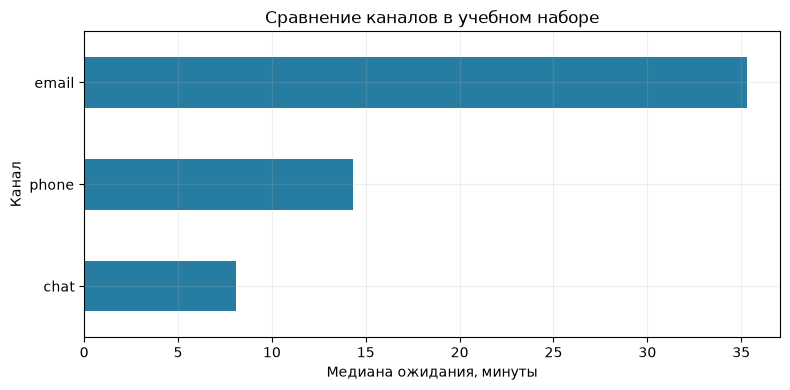

In [6]:
by_channel = tickets.groupby("channel").agg(
    n=("ticket_id", "size"), mean_wait=("wait_minutes", "mean"),
    median_wait=("wait_minutes", "median"), p90_wait=("wait_minutes", lambda s: s.quantile(0.9)))
display(by_channel.round(2))
assert by_channel["n"].sum() == len(tickets)
ax = by_channel["median_wait"].sort_values().plot.barh(color="#277DA1")
ax.set(xlabel="Медиана ожидания, минуты", ylabel="Канал", title="Сравнение каналов в учебном наборе")
plt.tight_layout()
plt.show()


## 7. Избегаем ошибки среднего от средних

        Если группы разного размера, общий показатель нужно взвесить по числу обращений.
        Простое среднее трёх средних отвечает на вопрос о «среднем канале»,
        а взвешенное — о «среднем обращении».


In [7]:
unweighted = by_channel["mean_wait"].mean()
weighted = np.average(by_channel["mean_wait"], weights=by_channel["n"])
print(f"Среднее средних: {unweighted:.2f} мин")
print(f"Взвешенное среднее: {weighted:.2f} мин")
assert np.isclose(weighted, waits.mean())


Среднее средних: 19.08 мин
Взвешенное среднее: 18.06 мин


## 8. Переводим идеи в правильные типы задач

        | Вопрос | Тип задачи | Что требуется |
        |---|---|---|
        | Сколько ждали в январе? | Описательная аналитика | Исторические обращения |
        | Сколько будет ждать новое обращение? | Регрессия | Признаки, известные при поступлении |
        | Какую категорию назначить тексту? | Классификация | Тексты и проверенные метки |
        | Какие группы обращений похожи? | Кластеризация | Признаки и критерий полезности групп |
        | Сформировать ответ сотруднику | Генеративная AI-система | Контекст, проверка ответа и правила использования |

        Пока мы реализовали первую строку. Доступность данных, смысл метрики и цена ошибки
        важнее выбора звучного названия алгоритма.


In [8]:
# Проверяем простое правило сервиса: доля обращений с ожиданием более 20 минут.
# Порог 20 выбран как учебное условие, а не как найденный отраслевой стандарт.
threshold = 20.0
tickets = tickets.assign(long_wait=tickets["wait_minutes"] > threshold)
long_wait_share = tickets["long_wait"].mean()
print(f"Дольше {threshold:.0f} минут: {tickets['long_wait'].sum()} из {len(tickets)} ({long_wait_share:.1%})")
assert 0 <= long_wait_share <= 1


Дольше 20 минут: 46 из 150 (30.7%)


## 9. Простейшая контрольная точка перед будущим ML

        Предположим, прогноз нужен для более поздних обращений. Первые 100 строк используем
        как историю, последние 50 — как будущую проверку. Постоянный прогноз равен медиане истории.
        Это baseline: ориентир, с которым позже сравним обучаемые модели.
        Медиана и ошибка не должны вычисляться по одним и тем же наблюдениям.
        Здесь нет обещания качества: 50 синтетических обращений — только демонстрация процедуры.


In [9]:
history = tickets.iloc[:100].copy()
future = tickets.iloc[100:].copy()
baseline = history["wait_minutes"].median()
errors = (future["wait_minutes"] - baseline).abs()
print(f"Постоянный прогноз: {baseline:.2f} мин; MAE на следующих 50 обращениях: {errors.mean():.2f} мин")
assert history["created_date"].max() < future["created_date"].min()
assert set(history["ticket_id"]).isdisjoint(future["ticket_id"])


Постоянный прогноз: 13.65 мин; MAE на следующих 50 обращениях: 10.14 мин


## 10. Воспроизводимость: данные, код и окружение

        Seed задаёт последовательность псевдослучайных чисел, но не заменяет версии библиотек,
        исходный файл и порядок запуска ячеек. Хеш файла помогает обнаружить случайное изменение данных.
        Он не доказывает, что сами данные правильные.


In [10]:
sample_a = np.random.default_rng(SEED).choice(tickets["ticket_id"], size=5, replace=False)
sample_b = np.random.default_rng(SEED).choice(tickets["ticket_id"], size=5, replace=False)
assert np.array_equal(sample_a, sample_b)
run_manifest = {"dataset": data_path.name, "sha256": hashlib.sha256(data_path.read_bytes()).hexdigest(),
                "rows": len(tickets), "seed": SEED, "python": sys.version.split()[0],
                "numpy": np.__version__, "pandas": pd.__version__}
print(json.dumps(run_manifest, ensure_ascii=False, indent=2))


{
  "dataset": "support_tickets.csv",
  "sha256": "451f772b81176d84d87fa63c992a39399aad66322cdfb59515ae479e9e086c9d",
  "rows": 150,
  "seed": 42,
  "python": "3.12.14",
  "numpy": "2.5.4",
  "pandas": "3.0.6"
}


## 11. Git, Colab и карьерные роли

        Git хранит историю изменений файлов. Notebook хранит и код, и выводы, поэтому перед коммитом
        проверьте, что в нём нет токенов, персональных данных или случайных огромных результатов.
        Локально можно выполнить `git status`, затем добавить **конкретный свой файл** и создать commit.
        Репозиторий курса приватный: для Colab потребуется авторизация доступа к GitHub либо загрузка
        полного архива. Один ipynb без соседней папки `datasets` работать не обязан.

        Аналитик объясняет наблюдения; Data Scientist ставит и проверяет модели; ML Engineer организует
        обучение и применение; AI Engineer строит систему вокруг моделей. В небольшой команде роли пересекаются.
        После этого практикума напишите, какие действия вы уже смогли сделать самостоятельно.


In [11]:
# Итоговый отчёт использует вычисленные значения, а не числа, набранные вручную.
print(f"Изучено {len(tickets)} синтетических обращений.")
print(f"Медиана ожидания: {waits.median():.1f} мин; 90-й процентиль: {waits.quantile(0.9):.1f} мин.")
print(f"Доля долгих ожиданий по учебному порогу: {long_wait_share:.1%}.")
print("Ограничение: каналы не распределялись случайно, поэтому различие не является причинным эффектом.")


Изучено 150 синтетических обращений.
Медиана ожидания: 14.4 мин; 90-й процентиль: 36.4 мин.
Доля долгих ожиданий по учебному порогу: 30.7%.
Ограничение: каналы не распределялись случайно, поэтому различие не является причинным эффектом.


## Вопросы для обсуждения

        1. Почему `resolution_minutes` может стать утечкой при прогнозе в момент поступления?
        2. Какие два дополнительных поля помогли бы понять причины долгого ожидания?
        3. Почему вывод «добавим чат — время ожидания обязательно снизится» не следует из графика?
        4. Что нужно сохранить, чтобы одногруппник повторил расчёт через месяц?

        Теперь переходите к [Homework Week 01](../homework/Homework_Week_01.md).


## Документация и дальнейшее чтение

- [JupyterLab: работа с notebooks](https://jupyterlab.readthedocs.io/en/stable/user/notebook.html)
- [Python: вводный учебник](https://docs.python.org/3/tutorial/)
- [Pro Git: основы Git](https://git-scm.com/book/en/v2/Getting-Started-Git-Basics)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
